In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,accuracy_score,recall_score,precision_score
from sklearn.metrics import roc_curve

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("Baseline")

2026/07/26 22:56:20 INFO mlflow.tracking.fluent: Experiment with name 'Baseline' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1785099380917, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1785099380917, lifecycle_stage='active', name='Baseline', tags={}, trace_location=None, workspace='default'>

In [22]:
mlflow.sklearn.autolog()

path = "../data/processed/Bank_Churn_clean.csv"
df = pd.read_csv(path)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [23]:
TARGET = "Exited"
X = df.drop(columns=[TARGET])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(X, y , test_size = 0.2, stratify= y, random_state=42)

In [24]:
ohe = OneHotEncoder( handle_unknown='ignore')
cat_cols = ['Gender', 'Geography']

ohe.fit(X_train[cat_cols])
X_train_ohe = ohe.transform(X_train[cat_cols])
X_test_ohe = ohe.transform(X_test[cat_cols])

ohe_cols = ohe.get_feature_names_out(cat_cols)
X_train[ohe_cols] = pd.DataFrame(X_train_ohe.toarray(), columns=ohe_cols, index=X_train.index)
X_test[ohe_cols] = pd.DataFrame(X_test_ohe.toarray(), columns=ohe_cols, index=X_test.index)

X_train = X_train.drop(columns=cat_cols)
X_test = X_test.drop(columns=cat_cols)

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
with mlflow.start_run():
    lr = LogisticRegression(class_weight="balanced")
    lr.fit(X_train_scaled, y_train)

2026/07/26 22:56:21 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'


2026/07/26 22:56:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.datascience\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


🏃 View run languid-mouse-214 at: http://localhost:5000/#/experiments/2/runs/4fbef1eed2b54212a2f62c6715326b66
🧪 View experiment at: http://localhost:5000/#/experiments/2


Accuracy: 0.7135
Precision: 0.38722826086956524
Recall: 0.7002457002457002
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000

Matrice de confusion:


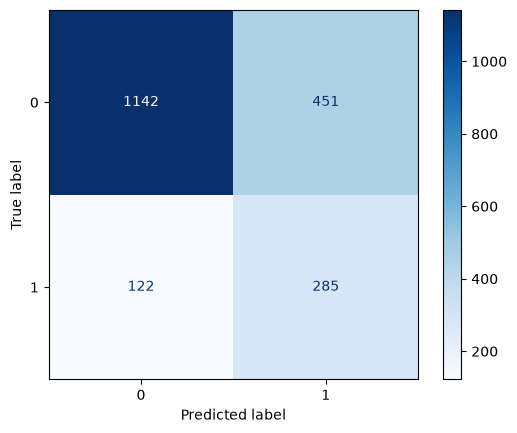

In [27]:
y_pred = lr.predict(X_test_scaled)
y_proba = lr.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:",accuracy_score(y_test, y_pred))
print("Precision:",precision_score(y_test, y_pred))
print("Recall:",recall_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

print("Matrice de confusion:")
confusion = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=lr.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.show() 

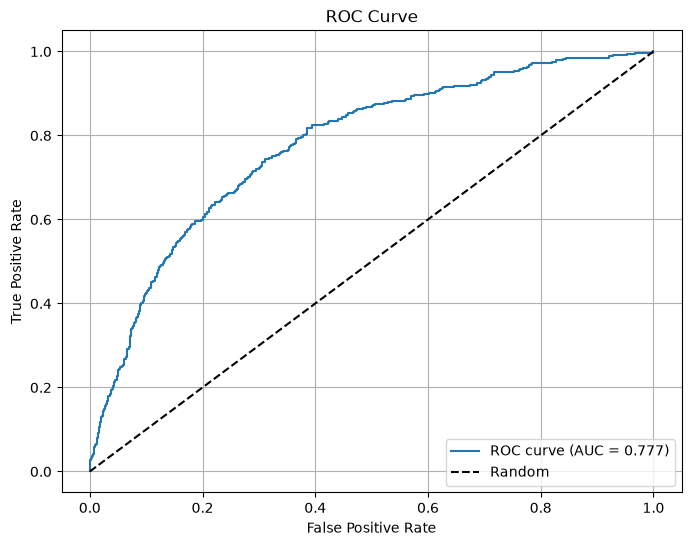

In [28]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(8, 6))
roc = roc_auc_score(y_test, y_proba)
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
joblib.dump({'model':lr}, "../models/baseline.pkl")